# 03 - Synthetic Control
**Owner:** Member 2 (Dhananjay) · **Week 2**

**Question:** how much extra revenue did North's price rise (from 1 May 2025) cause?

**Idea:** South and West never changed price. We find the mix of South and West that best copies North's revenue *before* 1 May. That mix is "synthetic North": our estimate of what North would have earned without the price change. After 1 May, the gap between real and synthetic North is the effect.

## Part 1 - Reshape the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

df = pd.read_csv("project1_algorithmic_pricing_synthetic_dataset.csv", parse_dates=["date"])

# One row per date, one revenue column per region
revenue = df.pivot(index="date", columns="region", values="revenue")
TREATMENT_DATE = pd.Timestamp("2025-05-01")
TREATED = "North"
DONORS = ["South", "West"]

print(revenue.shape)
revenue.head()

(180, 3)


region,North,South,West
date,,,
2025-01-01,50651.59,48937.65,60109.02
2025-01-02,54431.06,52101.37,62082.51
2025-01-03,62516.51,53274.36,57028.24
2025-01-04,67241.10,60980.94,65800.24
2025-01-05,66825.20,66908.57,69358.06


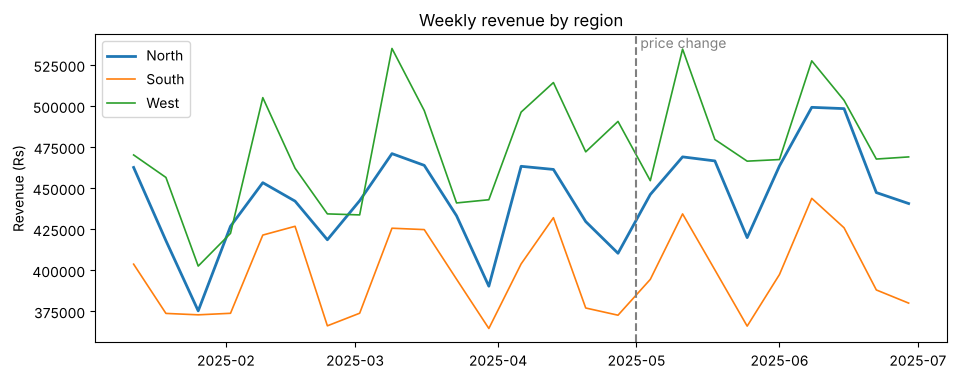

In [2]:
# Weekly totals smooth out day-to-day noise
weekly = revenue.resample("W-SUN").sum()
weekly = weekly[revenue.resample("W-SUN").size() == 7]   # keep full weeks only

fig, ax = plt.subplots(figsize=(11, 4))
for region in revenue.columns:
    ax.plot(weekly.index, weekly[region], label=region, linewidth=2 if region == TREATED else 1.2)
ax.axvline(TREATMENT_DATE, color="grey", linestyle="--")
ax.text(TREATMENT_DATE, ax.get_ylim()[1], " price change", va="top", color="grey")
ax.set_title("Weekly revenue by region")
ax.set_ylabel("Revenue (Rs)")
ax.legend()
plt.show()

## Part 2 - Find the donor weights
Weights must be between 0 and 1 and add up to 1, so synthetic North is a genuine blend of South and West. We pick the weights that make the pre-period gap as small as possible.

In [3]:
def fit_weights(data):
    pre = data.index < TREATMENT_DATE
    X = data.loc[pre, DONORS].values     # donor revenue before May
    y = data.loc[pre, TREATED].values    # North revenue before May

    scale = y.mean()                     # rescale so the optimiser works with numbers near 1

    def pre_period_error(w):
        return np.mean(((y - X @ w) / scale) ** 2)

    result = minimize(
        pre_period_error,
        x0=np.full(len(DONORS), 1 / len(DONORS)),
        bounds=[(0, 1)] * len(DONORS),
        constraints={"type": "eq", "fun": lambda w: w.sum() - 1},
    )
    return pd.Series(result.x, index=DONORS)

weights_daily = fit_weights(revenue)
print("Donor weights (daily data):")
print(weights_daily.round(3))
# Sanity check: weights must add up to 1
print("Sum of weights:", round(weights_daily.sum(), 3))

Donor weights (daily data):
South    0.522
West     0.478
dtype: float64
Sum of weights: 1.0
